In [23]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                             accuracy_score, roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer



In [24]:
df = pd.read_csv("C:\\Users\\Lenovo\\Downloads\\customer_churn.csv", keep_default_na=False, na_values=[""])
df.head()

,customer_id,age,gender,tenure_months,contract_type,internet_service,payment_method,support_calls,monthly_charges,total_charges,churn
0,C1000,76.0,Female,46,One year,Fiber optic,Credit card,1,78.04,3605.69,0
1,C1001,56.0,Male,63,One year,Fiber optic,Bank transfer,2,91.02,5713.27,0
2,C1002,60.0,Male,20,Month-to-month,Fiber optic,Bank transfer,2,97.65,1924.01,1
3,C1003,73.0,Female,64,Month-to-month,DSL,Mailed check,3,53.06,3360.42,0
4,C1004,53.0,Male,5,Month-to-month,Fiber optic,Electronic check,0,87.72,439.96,1


In [25]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nChurn rate:", round(df["churn"].mean(), 3))

Shape: (1000, 11)

Missing values:
 age               15
payment_method    10
total_charges     20
dtype: int64

Churn rate: 0.367


In [26]:
X = df.drop(columns=["customer_id", "churn"])
y = df["churn"]

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['age', 'tenure_months', 'support_calls', 'monthly_charges', 'total_charges']
Categorical columns: ['gender', 'contract_type', 'internet_service', 'payment_method']


In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [28]:
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])

In [29]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("rf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['age','gender','tenure_months',...,'support_calls','monthly_charges', 'total_charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrou

In [30]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC AUC :", round(roc_auc_score(y_test, y_proba), 4))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=["stayed", "churned"]))


Accuracy: 0.595
ROC AUC : 0.6308

Classification report:
               precision    recall  f1-score   support

      stayed       0.66      0.76      0.70       127
     churned       0.43      0.32      0.36        73

    accuracy                           0.59       200
   macro avg       0.54      0.54      0.53       200
weighted avg       0.57      0.59      0.58       200



In [31]:
model.score(X_test, y_test)

0.595

In [32]:
cv = cross_val_score(model, X, y, cv=5, scoring="roc_auc")
print("5-fold CV ROC AUC: %.3f (+/- %.3f)" % (cv.mean(), cv.std()))

5-fold CV ROC AUC: 0.687 (+/- 0.028)


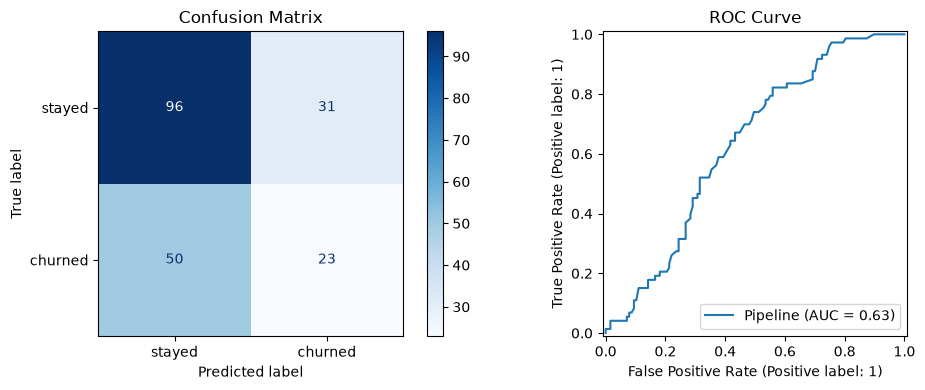

In [33]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["stayed", "churned"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax[1])
ax[1].set_title("ROC Curve")
plt.tight_layout()
plt.show()

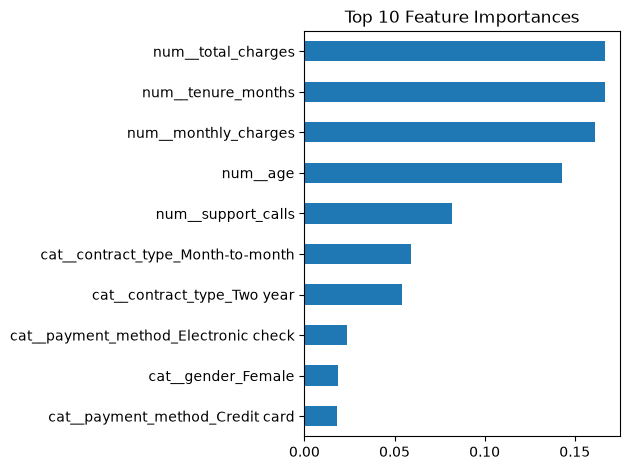

In [34]:
names = model[0].get_feature_names_out()
imp = pd.Series(model[-1].feature_importances_, index=names)
imp.nlargest(10).sort_values().plot(kind="barh", title="Top 10 Feature Importances")
plt.tight_layout()
plt.show()

In [35]:
param_grid = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_depth": [None, 5, 10],
    "rf__min_samples_leaf": [1, 3, 5],
}
grid = GridSearchCV(model, param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
print("\nBest params:", grid.best_params_)
print("Best CV ROC AUC:", round(grid.best_score_, 4))
print("Tuned test accuracy:", round(grid.score(X_test, y_test), 4))


Best params: {'rf__max_depth': 5, 'rf__min_samples_leaf': 3, 'rf__n_estimators': 300}
Best CV ROC AUC: 0.7442
Tuned test accuracy: 0.6806


In [37]:
new_customer = pd.DataFrame([{
    "age": 34, "gender": "Female", "tenure_months": 5,
    "contract_type": "Month-to-month", "internet_service": "Fiber optic",
    "payment_method": "Electronic check", "support_calls": 4,
    "monthly_charges": 85.0, "total_charges": 425.0,
}])
prob = model.predict_proba(new_customer)[0][1]
print("\nNew customer churn probability: %.2f" % prob)

joblib.dump(model, "churn_model.joblib")
loaded = joblib.load("churn_model.joblib")
print("Reloaded model prediction:", loaded.predict(new_customer)[0])


New customer churn probability: 0.68
Reloaded model prediction: 1
